In [1]:
from tensorflow.keras.models import load_model
import tensorflow as tf
from tensorflow.keras.utils import CustomObjectScope
from tensorflow.keras.initializers import glorot_uniform
from tensorflow.keras.layers import Layer 
from tensorflow.keras.utils import custom_object_scope
import cv2 
import numpy as np 
import matplotlib.pyplot as plt 

In [2]:
MODEL_PATH =  "./models/tf_model.hdf5"

In [3]:
tf.__version__

'2.18.0'

In [4]:
class CustomScaleLayer(tf.keras.layers.Layer):
    def __init__(self, scale=1.0, **kwargs):
        super(CustomScaleLayer, self).__init__(**kwargs)
        self.scale = scale

    def call(self, inputs, **kwargs):
        if isinstance(inputs, list):
            # Apply scale to each tensor
            return [x * self.scale for x in inputs]
        else:
            return inputs * self.scale

    def compute_output_shape(self, input_shape):
        return input_shape

    def get_config(self):
        config = super().get_config()
        config.update({'scale': self.scale})
        return config


In [5]:
with custom_object_scope({'CustomScaleLayer': CustomScaleLayer}):
    model = load_model(MODEL_PATH)

In [6]:
model.compile(loss="categorical_crossentropy",optimizer="adam",metrics=["acc"])

In [7]:
CLASSES  = ['Baked Potato', 'Burger', 'Donut', 'Fries', 'Hot Dog', 'Pizza', 'Sandwich']

In [27]:
def show_img(img,resize=True):
    img =  cv2.imread(img)
    img  = cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
    if resize:
        img =  cv2.resize(img,(300,300))
    plt.imshow(img)
    plt.axis("off")
    
    

In [35]:
def predict_img(img,argmax=True):
    img  = cv2.imread(img)
    img =  cv2.resize(img,(300,300))
    img  =  img.astype("float32") / 255.0
    img  = np.expand_dims(img,axis=0)
    preds  =  model.predict(img)
    if argmax :
        preds =  np.argmax(preds,axis=1)

    
    return preds

In [49]:
import os
for i in os.listdir("./media/"):
    if  i.endswith("jpeg"):
        pred =  predict_img(f"./media/{i}")
        print(f"{i} : {pred[0]}")
    
    

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 234ms/step
burger_1.jpeg : 2
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 280ms/step
burger_@.jpeg : 2
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 288ms/step
Donut.jpeg : 2
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 256ms/step
image1.jpeg : 2
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step
image2.jpeg : 2
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 248ms/step
image4.jpeg : 2


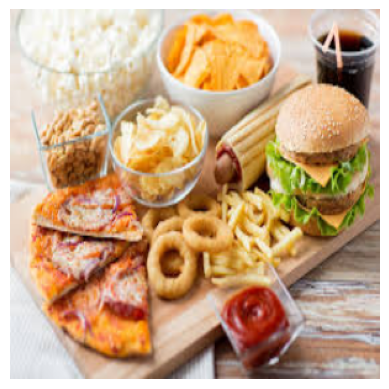

In [28]:
show_img("./media/image2.jpeg")

In [44]:
for i in os.listdir("./media/"):
    print(i)

burger_1.jpeg
burger_@.jpeg
Donut.jpeg
donut_2.png
image1.jpeg
image2.jpeg
image4.jpeg
JunkFood.mp4
JunkFood2.mp4
